# Gravity Model: Ransomware Detection and Evaluation


**Pipeline:** data validation → behavioral-domain masses → Gravity Model features → validation-based alpha selection → baseline/Gravity/combined classifiers → untouched test evaluation → influential-sample ranking → plots and CSV exports.

> The notebook uses the dataset's existing `label` column as ground truth. It does not create labels. Confirm the label mapping printed below before interpreting class 1 as ransomware.

In [1]:
# 1. Setup
import os, warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    average_precision_score, ConfusionMatrixDisplay,
    RocCurveDisplay, PrecisionRecallDisplay
)
from sklearn.impute import SimpleImputer

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
DATA_PATH = "/content/drive/MyDrive/RanDS_Complete_Dataset.xlsx"

try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception:
    print("Google Drive mount skipped (not running in Colab).")

if not os.path.exists(DATA_PATH):
    from google.colab import files
    print("Upload RanDS_Complete_Dataset.xlsx")
    uploaded = files.upload()
    DATA_PATH = next(iter(uploaded))

df = pd.read_excel(DATA_PATH)
df.columns = df.columns.astype(str).str.strip()
print("Dataset shape:", df.shape)
display(df.head())

Mounted at /content/drive
Dataset shape: (94427, 56)


,SHA256,label,accessed_registry_keys_count,accessed_registry_keys_unique,created_registry_keys_count,created_registry_keys_unique,accessed_files_count,accessed_files_unique,created_files_count,created_files_unique,...,graph_mean_k_shell,graph_max_eigenvector,graph_mean_eigenvector,graph_mean_krylov_1,graph_mean_krylov_2,graph_mean_krylov_3,graph_max_krylov_1,graph_max_krylov_2,graph_max_krylov_3,largest_component_nodes
0,000028670db2a67449efeaa1a6e96afe1124094bb61231...,0,0,0,0,0,0,0,0,0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0
1,000035645986fa547eef7affe06dac44eedaf0cb4c7e15...,1,318,318,40,40,241,241,52,52,...,1.000000,0.707107,0.669451,0.662713,0.671719,0.662713,0.816497,0.707107,0.816497,3.0
2,0000361f90000ceca0b05e840fca7b7cc535a0e7867207...,1,784,784,38,38,403,403,18,18,...,1.000000,0.707107,0.707107,0.707107,0.707107,0.707107,0.707107,0.707107,0.707107,2.0
3,000078e2a88d23f8c388cc286218efcf7547fb3ce3f3fe...,0,44,44,0,0,31,31,0,0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0
4,0000e8bfdd41e01fb3d36315502ac76c5553905a3abdd6...,1,378,378,62,62,302,302,24,24,...,1.266667,0.707107,0.616929,0.614146,0.618269,0.614901,0.707107,0.707107,0.707107,5.0


## 2. Validate labels and feature columns

The expected label column is `label`; `SHA256` is an identifier and is never used as a predictive feature. The eight behavioral domains below follow the domain organization in the supplied notebook.

In [2]:
if "label" not in df.columns:
    raise KeyError("Required target column 'label' was not found.")

print("Label counts (raw):")
display(df["label"].value_counts(dropna=False).to_frame("count"))

# Convert common binary encodings to 0/1 without silently guessing unknown labels.
if pd.api.types.is_numeric_dtype(df["label"]):
    y_all = pd.to_numeric(df["label"], errors="coerce")
else:
    label_map = {
        "benign": 0, "normal": 0, "good": 0, "0": 0,
        "malware": 1, "ransomware": 1, "malicious": 1, "bad": 1, "1": 1
    }
    y_all = df["label"].astype(str).str.strip().str.lower().map(label_map)

valid = y_all.notna()
df = df.loc[valid].copy()
y_all = y_all.loc[valid].astype(int)
classes = sorted(y_all.unique().tolist())
if len(classes) != 2 or classes != [0, 1]:
    raise ValueError(f"Expected binary labels encoded as 0 and 1; found {classes}. Map labels explicitly.")
print("Confirmed mapping: 0 = benign/negative, 1 = ransomware/positive (verify against dataset documentation).")
display(y_all.value_counts().rename(index={0:"0 / negative",1:"1 / positive"}).to_frame("samples"))

groups = {
    "registry": ["accessed_registry_keys_count","accessed_registry_keys_unique","created_registry_keys_count","created_registry_keys_unique"],
    "file": ["accessed_files_count","accessed_files_unique","created_files_count","created_files_unique","deleted_files_count","deleted_files_unique","changed_files_count","changed_files_unique"],
    "process": ["created_process_count","created_process_unique","killed_process_count","killed_process_unique","processes_tree_count","processes_tree_unique"],
    "mutex": ["accessed_mutexes_count","accessed_mutexes_unique","created_mutexes_count","created_mutexes_unique"],
    "module": ["loaded_modules_count","loaded_modules_unique"],
    "api": ["executed_commands_count","executed_commands_unique","critical_api_calls_count","critical_api_calls_unique"],
    "network": ["network_traffic_ips_count","network_traffic_ips_unique","network_dns_lookups_count","network_dns_lookups_unique","network_unique_ips","network_unique_ports","network_tcp_count","network_udp_count","network_icmp_count"],
    "graph": ["graph_nodes","graph_edges","graph_density","graph_components","graph_average_degree","graph_max_degree","graph_max_k_shell","graph_mean_k_shell","graph_max_eigenvector","graph_mean_eigenvector","graph_mean_krylov_1","graph_mean_krylov_2","graph_mean_krylov_3","graph_max_krylov_1","graph_max_krylov_2","graph_max_krylov_3","largest_component_nodes"]
}
available_groups = {}
for domain, cols in groups.items():
    present = [c for c in cols if c in df.columns]
    missing = sorted(set(cols) - set(present))
    if missing:
        print(f"{domain}: excluding {len(missing)} absent columns")
    if present:
        available_groups[domain] = present
    else:
        print(f"WARNING: domain '{domain}' has no columns and will be skipped.")

if len(available_groups) < 2:
    raise ValueError("At least two behavioral domains with available columns are needed for domain-to-domain Gravity interactions.")

feature_cols = list(dict.fromkeys(c for cols in available_groups.values() for c in cols))
X_all = df[feature_cols].apply(pd.to_numeric, errors="coerce")
X_all = X_all.replace([np.inf, -np.inf], np.nan)
print("Usable domains:", {k:len(v) for k,v in available_groups.items()})
print("Feature count:", len(feature_cols))
print("Duplicate SHA256 values:", int(df["SHA256"].duplicated().sum()) if "SHA256" in df.columns else "SHA256 column unavailable")

Label counts (raw):


,count
label,
1,51985
0,42442


Confirmed mapping: 0 = benign/negative, 1 = ransomware/positive (verify against dataset documentation).


,samples
label,
1 / positive,51985
0 / negative,42442


Usable domains: {'registry': 4, 'file': 8, 'process': 6, 'mutex': 4, 'module': 2, 'api': 4, 'network': 9, 'graph': 17}
Feature count: 54
Duplicate SHA256 values: 0


## 3. Split before fitting preprocessing

A 60/20/20 train/validation/test split is used. Alpha is selected on validation F1; the test set is held out for final reporting. If the dataset contains repeated executions of the same binary, use a hash-grouped split in a separate experiment to measure generalization to unseen binaries.

In [3]:
X_train_raw, X_temp_raw, y_train, y_temp = train_test_split(
    X_all, y_all, test_size=0.40, random_state=RANDOM_STATE, stratify=y_all
)
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp_raw, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp
)

imputer = SimpleImputer(strategy="median", keep_empty_features=True)
X_train = pd.DataFrame(imputer.fit_transform(X_train_raw), columns=feature_cols, index=X_train_raw.index)
X_val = pd.DataFrame(imputer.transform(X_val_raw), columns=feature_cols, index=X_val_raw.index)
X_test = pd.DataFrame(imputer.transform(X_test_raw), columns=feature_cols, index=X_test_raw.index)

# Activity counts/structural measures are expected to be nonnegative.
# Preserve legitimate negative values if any are present; log1p is applied only after clipping domain inputs.
print("Split sizes:", len(X_train), len(X_val), len(X_test))
print("Train labels:", y_train.value_counts().to_dict())
print("Validation labels:", y_val.value_counts().to_dict())
print("Test labels:", y_test.value_counts().to_dict())

Split sizes: 56656 18885 18886
Train labels: {1: 31191, 0: 25465}
Validation labels: {1: 10397, 0: 8488}
Test labels: {1: 10397, 0: 8489}


## 4. Behavioral mass and Gravity Model V2

For each sample and behavioral domain, mass is the sum of `log(1 + feature)` over that domain. Within each sample, domain masses are normalized to proportions. For domains *i* and *j*, the interaction distance is `sqrt((p_i - p_j)^2 + delta^2)` and force is `M_i M_j / distance^alpha`. The resulting pairwise interactions become sample-level Gravity features.

This is a domain-interaction feature model: the dataset's `graph_*` columns are graph summaries. It does **not** reconstruct an IP-to-IP communication graph or identify actual network nodes unless edge-level data is supplied.

In [4]:
def calculate_masses(X, domain_groups):
    out = pd.DataFrame(index=X.index)
    for domain, cols in domain_groups.items():
        vals = X[cols].clip(lower=0)
        out[domain] = np.log1p(vals).sum(axis=1)
    return out

M_train = calculate_masses(X_train, available_groups)
M_val = calculate_masses(X_val, available_groups)
M_test = calculate_masses(X_test, available_groups)

def gravity_features(masses, alpha=2.0, delta=0.05):
    domains = list(masses.columns)
    totals = masses.sum(axis=1).replace(0, np.nan)
    proportions = masses.div(totals, axis=0).fillna(0)
    out = pd.DataFrame(index=masses.index)
    pair_cols = []

    for i in range(len(domains)):
        for j in range(i + 1, len(domains)):
            a, b = domains[i], domains[j]
            mi, mj = masses[a].to_numpy(), masses[b].to_numpy()
            pi, pj = proportions[a].to_numpy(), proportions[b].to_numpy()
            d = np.sqrt((pi - pj)**2 + delta**2)
            force = (mi * mj) / np.maximum(d, 1e-12)**alpha
            name = f"gravity_{a}_{b}"
            out[name] = force
            pair_cols.append(name)

    forces = out[pair_cols].to_numpy()
    total = forces.sum(axis=1)
    shares = forces / np.maximum(total[:, None], 1e-12)
    out["gravity_total"] = total
    out["gravity_max"] = forces.max(axis=1) if forces.shape[1] else 0
    out["gravity_mean"] = forces.mean(axis=1) if forces.shape[1] else 0
    out["gravity_std"] = forces.std(axis=1) if forces.shape[1] else 0
    out["gravity_concentration"] = (shares**2).sum(axis=1)
    return out.replace([np.inf,-np.inf], 0).fillna(0)

ALPHA_VALUES = [1.0, 1.5, 2.0, 2.5]

## 5. Validation-based alpha selection and model comparison

Three feature configurations are compared: original behavioral features, Gravity-only features, and combined original + Gravity features. For each alpha, a Random Forest is fitted on the training split and evaluated on validation data. The best alpha is chosen using combined-model validation F1, not test performance.

In [5]:
def make_model():
    return RandomForestClassifier(
        n_estimators=300, max_features="sqrt",
        class_weight="balanced", random_state=RANDOM_STATE,
        n_jobs=-1
    )

validation_rows = []
validation_models = {}
gravity_cache = {}

for alpha in ALPHA_VALUES:
    Gtr = gravity_features(M_train, alpha)
    Gv = gravity_features(M_val, alpha)
    gravity_cache[alpha] = (Gtr, Gv, gravity_features(M_test, alpha))
    configs = {
        "Original": (X_train, X_val),
        "Gravity": (Gtr, Gv),
        "Combined": (pd.concat([X_train,Gtr],axis=1), pd.concat([X_val,Gv],axis=1))
    }
    for exp, (tr, va) in configs.items():
        model = make_model()
        model.fit(tr, y_train)
        pred = model.predict(va)
        prob = model.predict_proba(va)[:,1]
        f1 = f1_score(y_val, pred, zero_division=0)
        validation_rows.append({
            "Alpha": alpha, "Experiment": exp,
            "Accuracy": accuracy_score(y_val,pred),
            "Precision": precision_score(y_val,pred,zero_division=0),
            "Recall": recall_score(y_val,pred,zero_division=0),
            "F1": f1,
            "PR_AUC": average_precision_score(y_val,prob),
            "ROC_AUC": roc_auc_score(y_val,prob)
        })
        validation_models[(alpha,exp)] = model

validation_results = pd.DataFrame(validation_rows)
display(validation_results.sort_values(["Experiment","F1"],ascending=[True,False]).round(4))
best_alpha = (validation_results[validation_results.Experiment=="Combined"]
              .sort_values("F1",ascending=False).iloc[0]["Alpha"])
print("Selected alpha (validation combined F1):", best_alpha)

,Alpha,Experiment,Accuracy,Precision,Recall,F1,PR_AUC,ROC_AUC
8,2.0,Combined,0.9655,0.9651,0.9726,0.9688,0.9950,0.9939
11,2.5,Combined,0.9655,0.9646,0.9730,0.9688,0.9950,0.9939
5,1.5,Combined,0.9654,0.9657,0.9717,0.9687,0.9952,0.9939
2,1.0,Combined,0.9649,0.9651,0.9714,0.9683,0.9951,0.9939
7,2.0,Gravity,0.9417,0.9363,0.9593,0.9477,0.9877,0.9858
10,2.5,Gravity,0.9415,0.9362,0.9592,0.9476,0.9879,0.9857
4,1.5,Gravity,0.9412,0.9359,0.9588,0.9472,0.9882,0.9859
1,1.0,Gravity,0.9401,0.9370,0.9554,0.9461,0.9875,0.9854
0,1.0,Original,0.9683,0.9690,0.9736,0.9713,0.9959,0.9948
3,1.5,Original,0.9683,0.9690,0.9736,0.9713,0.9959,0.9948


Selected alpha (validation combined F1): 2.0


## 6. Final evaluation on untouched test data

The final models are trained using training + validation data, then evaluated once on the test set. The reported metrics include accuracy, precision, recall, F1, PR-AUC, ROC-AUC, and confusion matrices.

In [6]:
Gtr_best, Gv_best, Gte_best = gravity_cache[best_alpha]
X_fit = pd.concat([X_train, X_val])
y_fit = pd.concat([y_train, y_val])
G_fit = gravity_features(pd.concat([M_train,M_val]), best_alpha)

final_configs = {
    "Original": (X_fit, X_test),
    "Gravity": (G_fit, Gte_best),
    "Combined": (pd.concat([X_fit,G_fit],axis=1), pd.concat([X_test,Gte_best],axis=1))
}
final_models, final_predictions, final_probabilities = {}, {}, {}
test_rows = []

for name, (tr, te) in final_configs.items():
    model = make_model()
    model.fit(tr, y_fit)
    pred = model.predict(te)
    prob = model.predict_proba(te)[:,1]
    final_models[name] = model
    final_predictions[name] = pred
    final_probabilities[name] = prob
    test_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test,pred),
        "Precision": precision_score(y_test,pred,zero_division=0),
        "Recall": recall_score(y_test,pred,zero_division=0),
        "F1": f1_score(y_test,pred,zero_division=0),
        "PR_AUC": average_precision_score(y_test,prob),
        "ROC_AUC": roc_auc_score(y_test,prob)
    })

test_results = pd.DataFrame(test_rows)
display(test_results.round(5))
print("\nCombined model classification report:")
print(classification_report(y_test, final_predictions["Combined"], target_names=["Benign (0)","Ransomware (1)"], zero_division=0))

,Model,Accuracy,Precision,Recall,F1,PR_AUC,ROC_AUC
0,Original,0.96712,0.96838,0.97201,0.97019,0.99506,0.99432
1,Gravity,0.94541,0.94071,0.96143,0.95096,0.98795,0.98685
2,Combined,0.96489,0.96459,0.97191,0.96824,0.99467,0.99374



Combined model classification report:
                precision    recall  f1-score   support

    Benign (0)       0.97      0.96      0.96      8489
Ransomware (1)       0.96      0.97      0.97     10397

      accuracy                           0.96     18886
     macro avg       0.96      0.96      0.96     18886
  weighted avg       0.96      0.96      0.96     18886



## 7. Confusion matrices, ROC and Precision-Recall curves

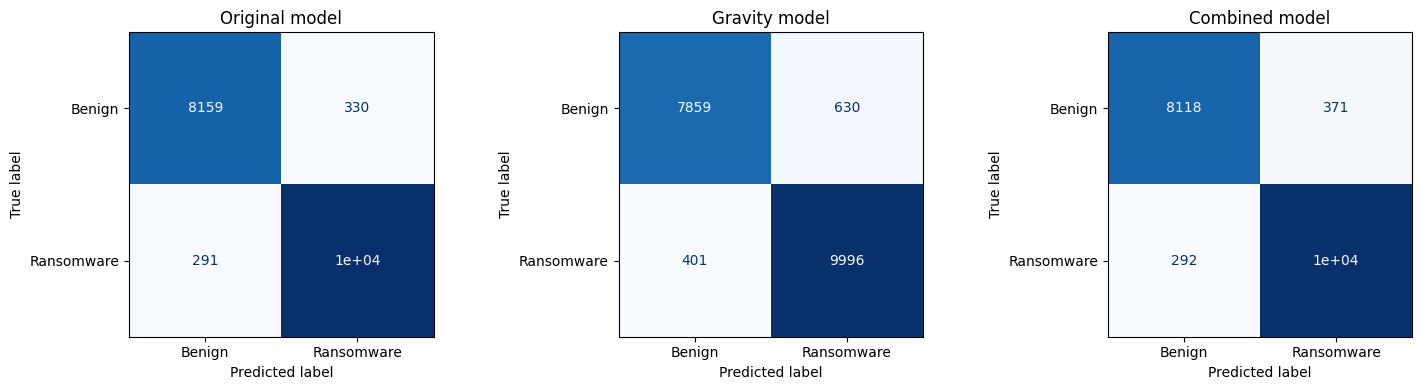

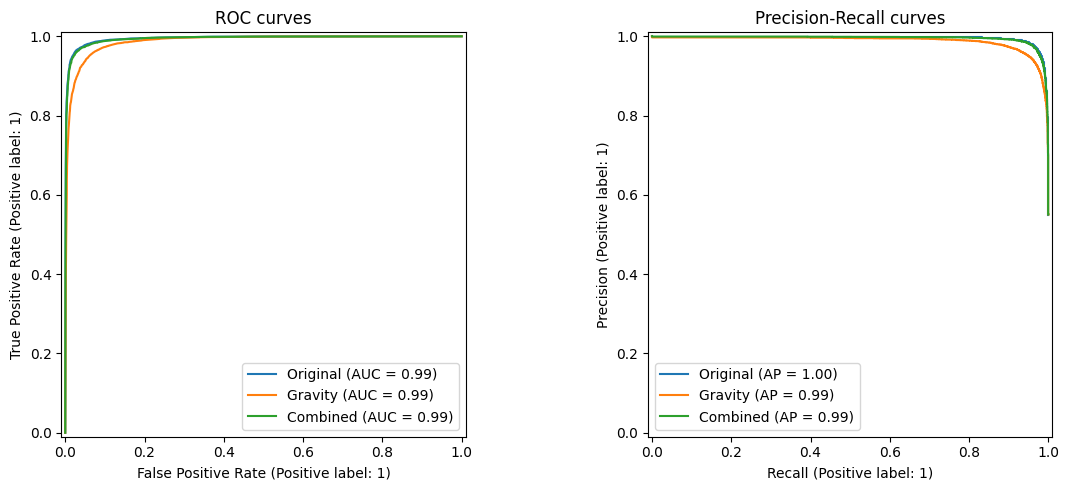

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15,4))
for ax, name in zip(axes, ["Original","Gravity","Combined"]):
    ConfusionMatrixDisplay.from_predictions(
        y_test, final_predictions[name],
        display_labels=["Benign","Ransomware"], cmap="Blues",
        colorbar=False, ax=ax
    )
    ax.set_title(f"{name} model")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1,2,figsize=(12,5))
for name in ["Original","Gravity","Combined"]:
    RocCurveDisplay.from_predictions(y_test, final_probabilities[name], name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, final_probabilities[name], name=name, ax=axes[1])
axes[0].set_title("ROC curves")
axes[1].set_title("Precision-Recall curves")
plt.tight_layout()
plt.show()

## 8. Gravity interaction network and domain influence

The following network is a visualization of **behavioral-domain interactions**, not a reconstructed malware communication topology. Edge weights are mean pairwise Gravity forces across test samples; node size represents mean domain mass.

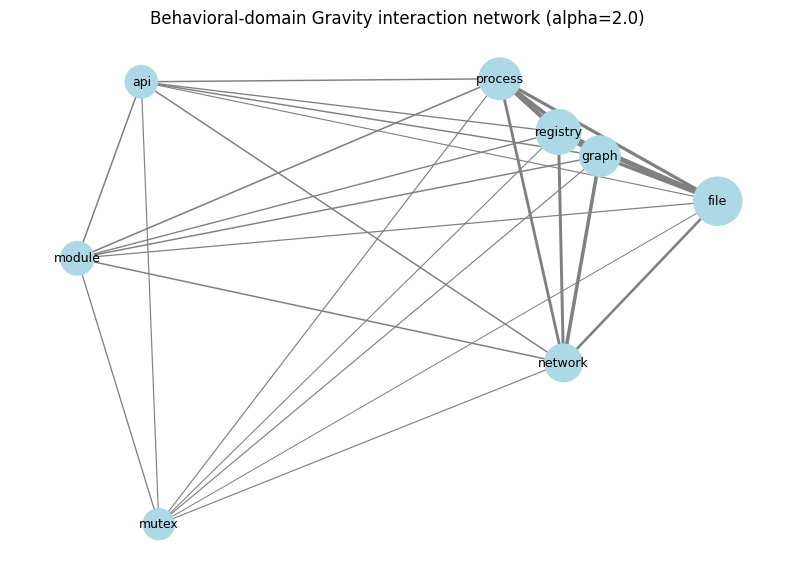

,Domain,Mean_Gravity_Influence
0,registry,167388.880051
7,graph,156952.364646
2,process,149171.217592
1,file,141189.935361
6,network,125881.642722
4,module,57913.584098
5,api,53291.307036
3,mutex,36049.280234


In [8]:
G_test_features = gravity_features(M_test, best_alpha)
domain_means = M_test.mean()
H = nx.Graph()
for d in M_test.columns:
    H.add_node(d, mass=float(domain_means[d]))
for i, a in enumerate(M_test.columns):
    for b in list(M_test.columns)[i+1:]:
        col = f"gravity_{a}_{b}"
        if col in G_test_features:
            H.add_edge(a,b,weight=float(G_test_features[col].mean()))

plt.figure(figsize=(10,7))
pos = nx.spring_layout(H, seed=RANDOM_STATE, weight="weight")
node_sizes = [300 + 900*H.nodes[n]["mass"]/(max(domain_means.max(),1e-9)) for n in H.nodes]
edge_widths = [0.5 + 3*H.edges[e]["weight"]/(max([x["weight"] for _,_,x in H.edges(data=True)] or [1])) for e in H.edges]
nx.draw_networkx(H,pos,node_size=node_sizes,width=edge_widths,with_labels=True,
                 font_size=9,node_color="lightblue",edge_color="gray")
plt.title(f"Behavioral-domain Gravity interaction network (alpha={best_alpha})")
plt.axis("off")
plt.show()

# Rank domains by average pairwise influence contribution.
pair_cols = [c for c in G_test_features if c.startswith("gravity_") and c not in
             ["gravity_total","gravity_max","gravity_mean","gravity_std","gravity_concentration"]]
domain_influence = {d:0.0 for d in M_test.columns}
for col in pair_cols:
    parts = col.replace("gravity_","",1).split("_",1)
    if len(parts)==2:
        a,b=parts
        if a in domain_influence: domain_influence[a] += G_test_features[col].mean()
        if b in domain_influence: domain_influence[b] += G_test_features[col].mean()
domain_influence_df = pd.DataFrame({"Domain":list(domain_influence),"Mean_Gravity_Influence":list(domain_influence.values())}).sort_values("Mean_Gravity_Influence",ascending=False)
display(domain_influence_df)

## 9. Influential sample ranking

Samples are ranked by their combined model ransomware probability and by their Gravity score. This is a sample-level risk ranking; it must not be described as ranking individual IP addresses or communication nodes.

,SHA256,true_label,predicted_label,ransomware_probability,gravity_score,gravity_rank,risk_rank
36212,4230a8f198f2a82d5bc5f3c2d3d0ccb52daa1b4a869fe7...,1,1,1.0,7.108414e+05,4863,1
50524,5a925dd08badf3436cb55fc88cf7cbea994d3a02f7b3fe...,1,1,1.0,8.557928e+05,3489,1
10923,11e891b4aa8a6272e5756ae7087510b456df2064a057ab...,1,1,1.0,1.173096e+06,1518,1
36386,427decd0986270b1f3459b61c38d3abcbd68d3a1fb08ea...,1,1,1.0,1.294925e+06,1013,1
11481,13030c81f34c23d108f94b544702a0fe891e2a8b4c6a61...,1,1,1.0,1.106250e+06,1849,1
81305,cba28f8f5fdb89f8574a3da19c0ee289b1f7b4e8fe2387...,1,1,1.0,7.253514e+05,4722,1
21031,2679317c4f1da6dbb88b55c427a52b49d7e9fb3a47f346...,1,1,1.0,4.835793e+05,7411,1
10886,11d67eda413d01d42c99543a58111547fd5f095789bd73...,1,1,1.0,7.034641e+05,4949,1
27595,334c5522b41fa28c3fae286cf9de7b32e97f2e743f6ce3...,1,1,1.0,9.211904e+05,2995,1
21318,2713d5f063d131de0d8ab8c4768401364b4f512c7b79cf...,1,1,1.0,4.256625e+05,8058,1


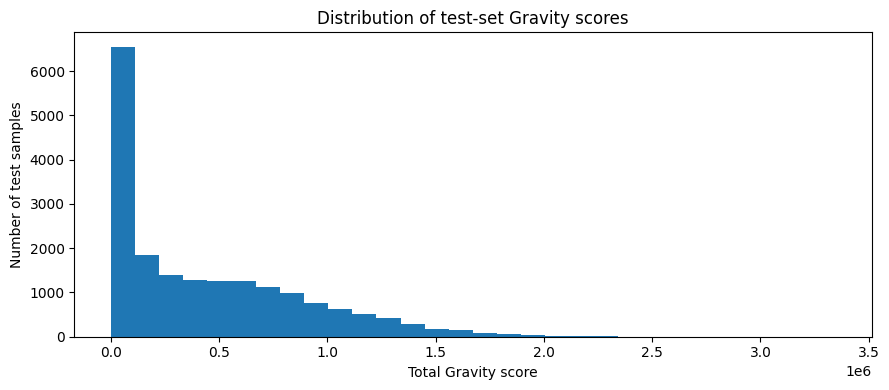

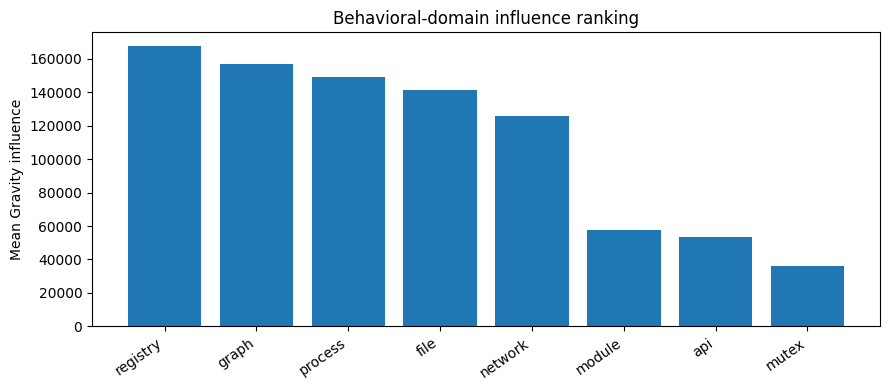

In [9]:
sample_rank = pd.DataFrame(index=X_test.index)
sample_rank["SHA256"] = df.loc[X_test.index,"SHA256"].astype(str) if "SHA256" in df.columns else X_test.index.astype(str)
sample_rank["true_label"] = y_test
sample_rank["predicted_label"] = final_predictions["Combined"]
sample_rank["ransomware_probability"] = final_probabilities["Combined"]
sample_rank["gravity_score"] = Gte_best["gravity_total"]
sample_rank["gravity_rank"] = sample_rank["gravity_score"].rank(method="min",ascending=False).astype(int)
sample_rank["risk_rank"] = sample_rank["ransomware_probability"].rank(method="min",ascending=False).astype(int)
sample_rank = sample_rank.sort_values("ransomware_probability",ascending=False)
display(sample_rank.head(20))

plt.figure(figsize=(9,4))
plt.hist(Gte_best["gravity_total"],bins=30)
plt.xlabel("Total Gravity score")
plt.ylabel("Number of test samples")
plt.title("Distribution of test-set Gravity scores")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9,4))
plt.bar(domain_influence_df["Domain"],domain_influence_df["Mean_Gravity_Influence"])
plt.xticks(rotation=35,ha="right")
plt.ylabel("Mean Gravity influence")
plt.title("Behavioral-domain influence ranking")
plt.tight_layout()
plt.show()

## 10. Feature importance and export research artifacts

,Feature,Importance
16,processes_tree_count,0.086339
17,processes_tree_unique,0.062367
76,gravity_module_api,0.057446
68,gravity_process_module,0.055322
84,gravity_mean,0.043284
82,gravity_total,0.040063
22,loaded_modules_count,0.033618
23,loaded_modules_unique,0.032201
78,gravity_module_graph,0.031848
77,gravity_module_network,0.030275


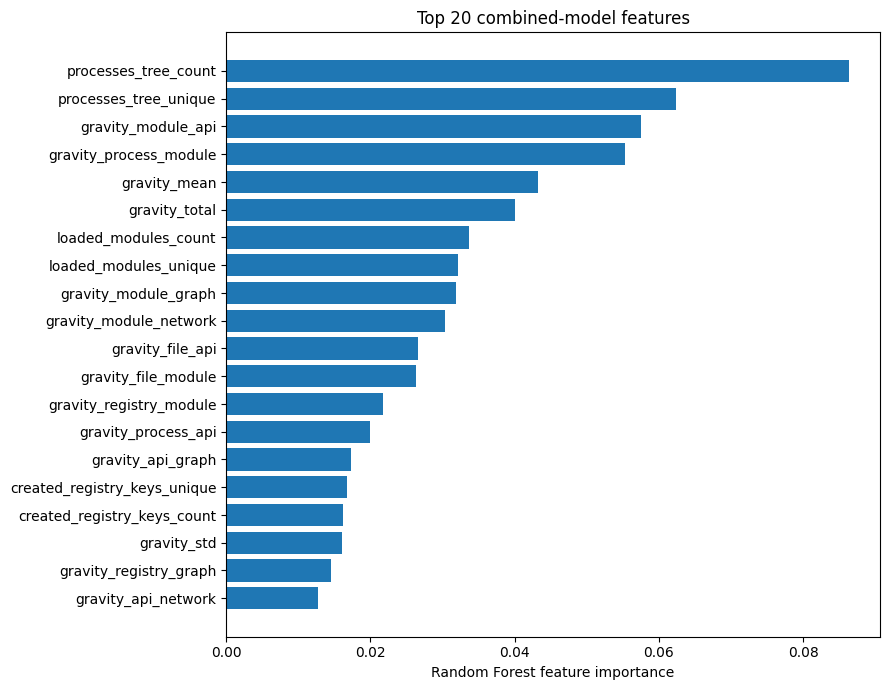

Saved outputs:
 - combined_feature_importance.csv
 - combined_test_predictions.csv
 - domain_influence_ranking.csv
 - final_test_metrics.csv
 - gravity_test_predictions.csv
 - influential_sample_ranking.csv
 - original_test_predictions.csv
 - validation_experiments.csv


In [10]:
combined_model = final_models["Combined"]
combined_feature_names = list(final_configs["Combined"][0].columns)
importance_df = pd.DataFrame({
    "Feature": combined_feature_names,
    "Importance": combined_model.feature_importances_
}).sort_values("Importance",ascending=False)

display(importance_df.head(25))
plt.figure(figsize=(9,7))
top = importance_df.head(20).sort_values("Importance")
plt.barh(top["Feature"],top["Importance"])
plt.xlabel("Random Forest feature importance")
plt.title("Top 20 combined-model features")
plt.tight_layout()
plt.show()

os.makedirs("gravity_outputs",exist_ok=True)
validation_results.to_csv("gravity_outputs/validation_experiments.csv",index=False)
test_results.to_csv("gravity_outputs/final_test_metrics.csv",index=False)
sample_rank.to_csv("gravity_outputs/influential_sample_ranking.csv",index=False)
domain_influence_df.to_csv("gravity_outputs/domain_influence_ranking.csv",index=False)
importance_df.to_csv("gravity_outputs/combined_feature_importance.csv",index=False)

for name in ["Original","Gravity","Combined"]:
    pd.DataFrame({
        "true_label":y_test,
        "predicted_label":final_predictions[name],
        "positive_probability":final_probabilities[name]
    },index=y_test.index).to_csv(f"gravity_outputs/{name.lower()}_test_predictions.csv")

print("Saved outputs:")
for f in sorted(os.listdir("gravity_outputs")):
    print(" -",f)

In [17]:
# Configure these paths and column names for your edge-level files.
EDGE_PATH = "network_edges.csv"       # Local file path instead of Google Drive
NODE_FEATURE_PATH = "node_features.csv"  # Optional local node feature file
TOP_K = 10
ALPHA_NODE = float(best_alpha) if "best_alpha" in globals() else 2.0

import os
import pandas as pd
import numpy as np
import networkx as nx
from sklearn.preprocessing import MinMaxScaler

def read_table(path):
    if path.lower().endswith((".xlsx", ".xls")):
        return pd.read_excel(path)
    return pd.read_csv(path)

if not os.path.exists(EDGE_PATH):
    raise FileNotFoundError(
        f"Edge file not found: {EDGE_PATH}. Please upload your '{EDGE_PATH}' "
        "using the Colab files panel on the left. It must contain source_ip and dest_ip columns."
    )

edges = read_table(EDGE_PATH)
edges.columns = edges.columns.astype(str).str.strip()
required_edge_cols = {"source_ip", "dest_ip"}
if not required_edge_cols.issubset(edges.columns):
    raise KeyError(f"Edge file must contain columns {required_edge_cols}; found {list(edges.columns)}")

edges = edges.dropna(subset=["source_ip", "dest_ip"]).copy()
edges["source_ip"] = edges["source_ip"].astype(str)
edges["dest_ip"] = edges["dest_ip"].astype(str)
edges = edges[edges["source_ip"] != edges["dest_ip"]]

# Build an undirected communication graph. Repeated flows become edge weights.
G_nodes = nx.Graph()
for s, d in zip(edges["source_ip"], edges["dest_ip"]):
    if G_nodes.has_edge(s, d):
        G_nodes[s][d]["weight"] += 1.0
    else:
        G_nodes.add_edge(s, d, weight=1.0)

if G_nodes.number_of_nodes() == 0:
    raise ValueError("No usable edges found in the edge file.")

print("Network nodes:", G_nodes.number_of_nodes())
print("Network edges:", G_nodes.number_of_edges())
print("Connected components:", nx.number_connected_components(G_nodes))

Network nodes: 66
Network edges: 446
Connected components: 1


In [15]:
from google.colab import files
import os

print("Please upload your 'network_edges.csv' file:")
uploaded = files.upload()

# Verify if the expected file was successfully uploaded
if "network_edges.csv" in uploaded:
    print("\nSuccess: 'network_edges.csv' uploaded successfully!")
else:
    uploaded_name = next(iter(uploaded)) if uploaded else None
    if uploaded_name:
        os.rename(uploaded_name, "network_edges.csv")
        print(f"\nRenamed uploaded file '{uploaded_name}' to 'network_edges.csv'")
    else:
        print("\nNo file was uploaded.")

Please upload your 'network_edges.csv' file:


Saving RanDS_Complete_Dataset.xlsx to RanDS_Complete_Dataset.xlsx

Renamed uploaded file 'RanDS_Complete_Dataset.xlsx' to 'network_edges.csv'


In [16]:
# Run this cell to generate a synthetic 'network_edges.csv' for demonstration purposes
import pandas as pd
import numpy as np

print("Generating a synthetic 'network_edges.csv' dataset...")
np.random.seed(42)

# Create some dummy IP addresses
ips = [f"192.168.1.{i}" for i in range(2, 50)] + [f"10.0.0.{i}" for i in range(2, 20)]

# Generate 500 synthetic flows (edges)
sources = np.random.choice(ips, size=500)
destinations = np.random.choice(ips, size=500)

df_edges = pd.DataFrame({
    "source_ip": sources,
    "dest_ip": destinations
})

# Drop self-loops
df_edges = df_edges[df_edges["source_ip"] != df_edges["dest_ip"]]

df_edges.to_csv("network_edges.csv", index=False)
print("Successfully created 'network_edges.csv' with columns: 'source_ip', 'dest_ip'")

Generating a synthetic 'network_edges.csv' dataset...
Successfully created 'network_edges.csv' with columns: 'source_ip', 'dest_ip'


In [13]:
import os

file_exists = os.path.exists("network_edges.csv")
print(f"'network_edges.csv' exists in current directory: {file_exists}")

print("\nAll files in current directory:")
for f in sorted(os.listdir('.')):
    if os.path.isfile(f):
        print(f" - {f}")

'network_edges.csv' exists in current directory: False

All files in current directory:


In [18]:
# 1) Structural node metrics
ks = nx.core_number(G_nodes) if G_nodes.number_of_edges() else {n: 0 for n in G_nodes}
try:
    eig = nx.eigenvector_centrality_numpy(G_nodes, weight="weight")
except Exception:
    eig = nx.degree_centrality(G_nodes)

# Krylov-style influence: aggregate A^k * 1 for k = 1,2,3.
node_order = list(G_nodes.nodes())
A = nx.to_numpy_array(G_nodes, nodelist=node_order, weight="weight", dtype=float)
row_sums = A.sum(axis=1, keepdims=True)
A_norm = np.divide(A, row_sums, out=np.zeros_like(A), where=row_sums != 0)
x = np.ones(len(node_order), dtype=float)
krylov_raw = np.zeros(len(node_order), dtype=float)
for _ in range(3):
    x = A_norm @ x
    krylov_raw += x

node_metrics = pd.DataFrame({
    "node_id": node_order,
    "k_shell": [ks[n] for n in node_order],
    "eigenvector": [eig[n] for n in node_order],
    "krylov": krylov_raw,
    "degree": [G_nodes.degree(n) for n in node_order],
    "weighted_degree": [G_nodes.degree(n, weight="weight") for n in node_order]
}).set_index("node_id")

def minmax_series(s):
    s = pd.to_numeric(s, errors="coerce").fillna(0).astype(float)
    lo, hi = s.min(), s.max()
    return (s - lo) / (hi - lo) if hi > lo else pd.Series(0.0, index=s.index)

node_metrics["k_shell_norm"] = minmax_series(node_metrics["k_shell"])
node_metrics["eigenvector_norm"] = minmax_series(node_metrics["eigenvector"])
node_metrics["krylov_norm"] = minmax_series(node_metrics["krylov"])

# Same weighted node-mass concept used in the research design.
node_metrics["node_mass"] = (
    0.4 * node_metrics["k_shell_norm"] +
    0.3 * node_metrics["eigenvector_norm"] +
    0.3 * node_metrics["krylov_norm"]
)

# 2) Gravity influence over shortest-path distances.
# Use connected-component paths only; unreachable node pairs contribute zero.
gravity_scores = pd.Series(0.0, index=node_metrics.index)
for component in nx.connected_components(G_nodes):
    sub = G_nodes.subgraph(component)
    component_nodes = list(component)
    masses = node_metrics.loc[component_nodes, "node_mass"]
    for source, lengths in nx.all_pairs_shortest_path_length(sub):
        mi = float(masses.loc[source])
        if mi <= 0:
            continue
        force_sum = 0.0
        for target, distance in lengths.items():
            if target == source or distance <= 0:
                continue
            mj = float(masses.loc[target])
            force_sum += (mi * mj) / (float(distance) ** ALPHA_NODE)
        gravity_scores.loc[source] = force_sum

node_metrics["gravity_score"] = gravity_scores
node_metrics["gravity_norm"] = minmax_series(node_metrics["gravity_score"])


In [19]:
# Optional node-level behavioral features.
node_features = None
if os.path.exists(NODE_FEATURE_PATH):
    node_features = read_table(NODE_FEATURE_PATH)
    node_features.columns = node_features.columns.astype(str).str.strip()
    if "node_id" not in node_features.columns:
        raise KeyError("Node feature file must contain a 'node_id' column.")
    node_features["node_id"] = node_features["node_id"].astype(str)

    if "behavior_score" in node_features.columns:
        behavior = pd.to_numeric(node_features["behavior_score"], errors="coerce")
        behavior_by_node = pd.DataFrame({
            "node_id": node_features["node_id"],
            "behavior_score": behavior
        }).groupby("node_id")["behavior_score"].mean()
        node_metrics["behavior_score"] = behavior_by_node.reindex(node_metrics.index).fillna(0)
    else:
        node_metrics["behavior_score"] = 0.0

    if "label" in node_features.columns:
        label_map_node = {
            "benign": 0, "normal": 0, "0": 0,
            "ransomware": 1, "malware": 1, "malicious": 1, "1": 1
        }
        raw = node_features[["node_id", "label"]].copy()
        raw["label_binary"] = raw["label"].astype(str).str.strip().str.lower().map(label_map_node)
        labels_by_node = raw.dropna(subset=["label_binary"]).groupby("node_id")["label_binary"].max()
        node_metrics["true_label"] = labels_by_node.reindex(node_metrics.index)
else:
    node_metrics["behavior_score"] = 0.0

node_metrics["behavior_norm"] = minmax_series(node_metrics["behavior_score"])

# Adaptive node risk score: Gravity propagation influence + observed behavior.
# If behavior scores are absent/all zero, the ranking is Gravity-only and is not a malware classifier.
if node_metrics["behavior_norm"].max() > 0:
    node_metrics["adaptive_risk_score"] = (
        0.5 * node_metrics["gravity_norm"] +
        0.5 * node_metrics["behavior_norm"]
    )
else:
    node_metrics["adaptive_risk_score"] = node_metrics["gravity_norm"]

has_node_labels = "true_label" in node_metrics.columns and node_metrics["true_label"].notna().any()
if has_node_labels:
    ransomware_pool = node_metrics[node_metrics["true_label"] == 1].copy()
    ranking_note = "Top-K among nodes labelled ransomware in the supplied node-level ground truth."
else:
    ransomware_pool = node_metrics.copy()
    ranking_note = "Unverified high-risk node candidates: no node-level ground-truth ransomware labels were supplied."

top_k_nodes = ransomware_pool.sort_values(
    ["adaptive_risk_score", "gravity_score"], ascending=False
).head(TOP_K).copy()
top_k_nodes.insert(0, "rank", range(1, len(top_k_nodes) + 1))

print(ranking_note)
display(top_k_nodes[[
    "rank", "adaptive_risk_score", "gravity_score", "node_mass",
    "k_shell", "eigenvector", "krylov", "degree", "weighted_degree",
    "behavior_score"
] + (["true_label"] if has_node_labels else [])])

os.makedirs("gravity_outputs", exist_ok=True)
top_k_nodes.to_csv("gravity_outputs/top_k_ransomware_nodes.csv", index=True, index_label="node_id")
node_metrics.to_csv("gravity_outputs/all_network_node_scores.csv", index=True, index_label="node_id")
print("Saved: gravity_outputs/top_k_ransomware_nodes.csv")
print("Saved: gravity_outputs/all_network_node_scores.csv")


Unverified high-risk node candidates: no node-level ground-truth ransomware labels were supplied.


,rank,adaptive_risk_score,gravity_score,node_mass,k_shell,eigenvector,krylov,degree,weighted_degree,behavior_score
node_id,,,,,,,,,,
10.0.0.15,1,1.000000,26.187037,1.000000,10,0.226927,3.0,22,26.0,0.0
192.168.1.34,2,0.915629,24.320872,0.958190,10,0.201123,3.0,21,24.0,0.0
192.168.1.2,3,0.855755,22.996531,0.981402,10,0.215449,3.0,18,24.0,0.0
10.0.0.4,4,0.854335,22.965136,0.920405,10,0.177803,3.0,21,24.0,0.0
10.0.0.16,5,0.799898,21.761055,0.910808,10,0.171881,3.0,18,20.0,0.0
192.168.1.20,6,0.739351,20.421847,0.873776,10,0.149026,3.0,18,18.0,0.0
192.168.1.48,7,0.738402,20.400863,0.867938,10,0.145422,3.0,18,19.0,0.0
192.168.1.39,8,0.716268,19.911283,0.862248,10,0.141911,3.0,18,20.0,0.0
192.168.1.18,9,0.709884,19.770076,0.864226,10,0.143132,3.0,18,19.0,0.0


Saved: gravity_outputs/top_k_ransomware_nodes.csv
Saved: gravity_outputs/all_network_node_scores.csv


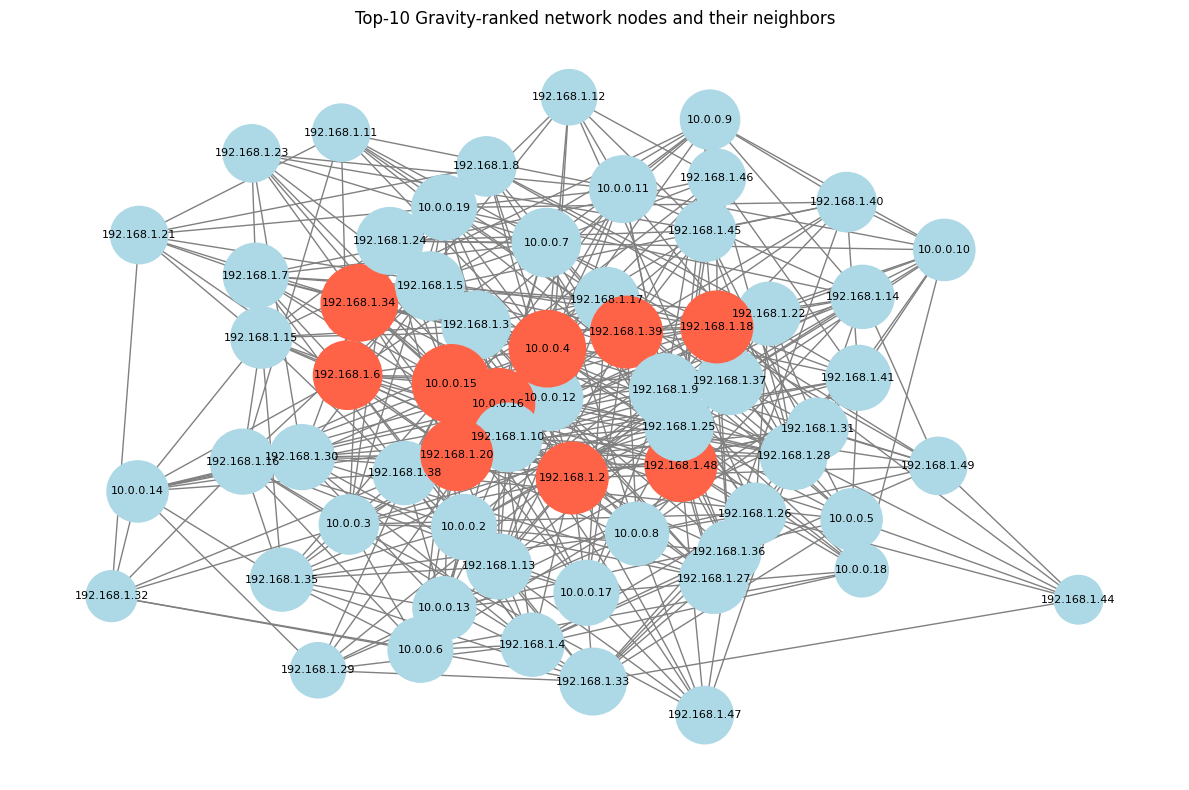

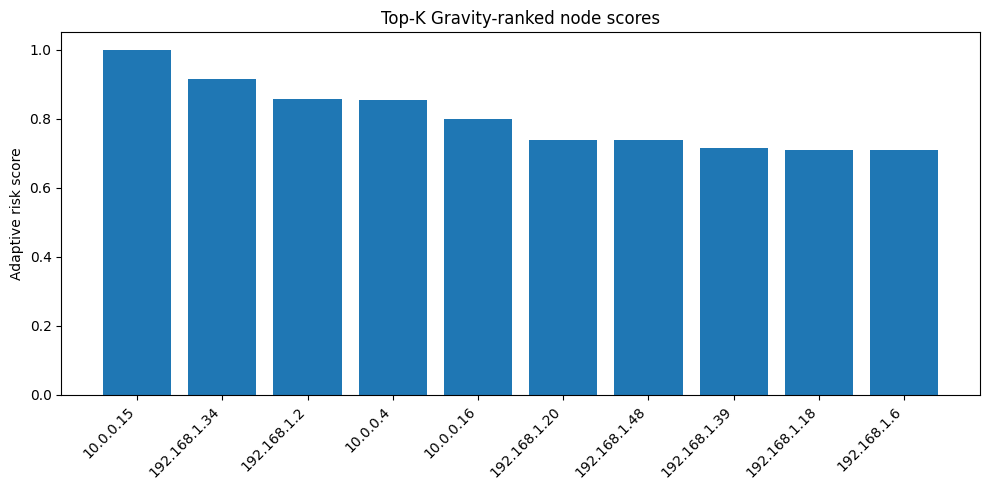

In [20]:
selected = top_k_nodes.index.astype(str).tolist()
plot_nodes = set(selected)
for n in selected:
    plot_nodes.update(G_nodes.neighbors(n))
H_top = G_nodes.subgraph(plot_nodes).copy()

plt.figure(figsize=(12, 8))
pos = nx.spring_layout(H_top, seed=RANDOM_STATE, weight="weight")
selected_colors = ["tomato" if n in selected else "lightblue" for n in H_top.nodes()]
sizes = [500 + 120 * G_nodes.degree(n) for n in H_top.nodes()]
nx.draw_networkx(
    H_top, pos, with_labels=True, node_color=selected_colors,
    node_size=sizes, font_size=8, edge_color="gray", width=1.0
)
plt.title(f"Top-{len(selected)} Gravity-ranked network nodes and their neighbors")
plt.axis("off")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.bar(top_k_nodes.index.astype(str), top_k_nodes["adaptive_risk_score"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("Adaptive risk score")
plt.title("Top-K Gravity-ranked node scores")
plt.tight_layout()
plt.show()


In [26]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

# ==========================================
# STEP 1: NETWORK GRAPH
# ==========================================

G = G_nodes

print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

nodes = list(G.nodes())

# ==========================================
# STEP 2: K-SHELL CENTRALITY
# ==========================================

k_shell = nx.core_number(G)

# ==========================================
# STEP 3: EIGENVECTOR CENTRALITY
# ==========================================

try:
    eigenvector = nx.eigenvector_centrality(
        G,
        max_iter=2000,
        weight="weight"
    )
except:
    eigenvector = nx.degree_centrality(G)

# ==========================================
# STEP 4: IMPROVED KRYLOV INFLUENCE
# ==========================================

A = nx.to_numpy_array(
    G,
    nodelist=nodes,
    weight="weight",
    dtype=float
)

# Calculate maximum absolute eigenvalue
eigenvalues = np.linalg.eigvalsh(A)
lambda_max = np.max(np.abs(eigenvalues))

# Normalize adjacency matrix
if lambda_max > 0:
    A_norm = A / lambda_max
else:
    A_norm = A.copy()

# Degree-weighted initial vector
degree = A.sum(axis=1)

x = np.sqrt(degree)

x = x / (np.linalg.norm(x) + 1e-12)

# Initialize Krylov influence
krylov = np.zeros(len(nodes))

# Three Krylov iterations
for i in range(3):
    x = A_norm @ x
    krylov += x

# Normalize scores
krylov = normalize(krylov)

print("Krylov influence calculated successfully!")

print("Unique Krylov scores:",
      len(np.unique(np.round(krylov, 8))))

# ==========================================
# STEP 5: NORMALIZATION
# ==========================================

def normalize(values):

    values = np.array(values, dtype=float)

    minimum = values.min()
    maximum = values.max()

    if maximum == minimum:
        return np.zeros_like(values)

    return (values - minimum) / (maximum - minimum)


ks_norm = normalize([k_shell[n] for n in nodes])

ev_norm = normalize([eigenvector[n] for n in nodes])

krylov_norm = normalize(krylov)

# ==========================================
# STEP 6: NODE MASS
# ==========================================

node_mass = (
    0.4 * ks_norm +
    0.3 * ev_norm +
    0.3 * krylov_norm
)

# ==========================================
# STEP 7: GRAVITY MODEL
# ==========================================

alpha = 2.0

gravity_scores = {}

# Calculate shortest-path distances
for source in nodes:

    gravity = 0

    distances = nx.single_source_shortest_path_length(
        G, source
    )

    source_index = nodes.index(source)
    mi = node_mass[source_index]

    for target, distance in distances.items():

        if source == target:
            continue

        target_index = nodes.index(target)
        mj = node_mass[target_index]

        gravity += (
            mi * mj
        ) / (distance ** alpha)

    gravity_scores[source] = gravity

# ==========================================
# STEP 8: CREATE COMPARISON DATAFRAME
# ==========================================

results = pd.DataFrame({

    "IP_Address": nodes,

    "K_Shell": [k_shell[n] for n in nodes],

    "Eigenvector": [eigenvector[n] for n in nodes],

    "Krylov": krylov,

    "Node_Mass": node_mass,

    "Gravity_Score": [
        gravity_scores[n] for n in nodes
    ]

})

# ==========================================
# STEP 9: CALCULATE RANKINGS
# ==========================================

results["K_Shell_Rank"] = (
    results["K_Shell"]
    .rank(ascending=False, method="min")
    .astype(int)
)

results["Eigenvector_Rank"] = (
    results["Eigenvector"]
    .rank(ascending=False, method="min")
    .astype(int)
)

results["Krylov_Rank"] = (
    results["Krylov"]
    .rank(ascending=False, method="min")
    .astype(int)
)

results["Gravity_Rank"] = (
    results["Gravity_Score"]
    .rank(ascending=False, method="min")
    .astype(int)
)

# ==========================================
# STEP 10: TOP-10 COMPARISON
# ==========================================

top10_ks = results.nsmallest(10, "K_Shell_Rank")

top10_ev = results.nsmallest(10, "Eigenvector_Rank")

top10_krylov = results.nsmallest(10, "Krylov_Rank")

top10_gravity = results.nsmallest(10, "Gravity_Rank")

comparison = pd.DataFrame({

    "Rank": range(1, 11),

    "K_Shell_Top10": top10_ks["IP_Address"].tolist(),

    "Eigenvector_Top10": top10_ev["IP_Address"].tolist(),

    "Krylov_Top10": top10_krylov["IP_Address"].tolist(),

    "Gravity_Top10": top10_gravity["IP_Address"].tolist()

})

print("\n========== TOP-10 NODE COMPARISON ==========")

display(comparison)

# ==========================================
# STEP 11: GRAVITY TOP-10 DETAILED RESULTS
# ==========================================

gravity_top10 = results.sort_values(
    "Gravity_Score",
    ascending=False
).head(10)

print("\n========== TOP-10 GRAVITY INFLUENTIAL NODES ==========")

display(gravity_top10)

# ==========================================
# STEP 12: SAVE RESULTS
# ==========================================

comparison.to_csv(
    "Top10_Centrality_Comparison.csv",
    index=False
)

results.to_csv(
    "All_Node_Centrality_Rankings.csv",
    index=False
)

gravity_top10.to_csv(
    "Top10_Gravity_Nodes.csv",
    index=False
)

print("All ranking results exported successfully!")

Number of nodes: 66
Number of edges: 446
Krylov influence calculated successfully!
Unique Krylov scores: 66

========== TOP-10 NODE COMPARISON ==========


,Rank,K_Shell_Top10,Eigenvector_Top10,Krylov_Top10,Gravity_Top10
0,1,10.0.0.5,10.0.0.15,10.0.0.15,10.0.0.15
1,2,192.168.1.48,192.168.1.2,192.168.1.2,192.168.1.34
2,3,192.168.1.16,192.168.1.34,192.168.1.34,192.168.1.2
3,4,10.0.0.2,10.0.0.4,10.0.0.4,10.0.0.4
4,5,10.0.0.14,10.0.0.16,10.0.0.16,10.0.0.16
5,6,192.168.1.15,192.168.1.13,192.168.1.3,192.168.1.20
6,7,192.168.1.22,192.168.1.3,192.168.1.13,192.168.1.48
7,8,192.168.1.25,192.168.1.20,192.168.1.6,192.168.1.3
8,9,192.168.1.4,192.168.1.6,192.168.1.37,192.168.1.6
9,10,192.168.1.2,192.168.1.37,192.168.1.20,192.168.1.39



========== TOP-10 GRAVITY INFLUENTIAL NODES ==========


,IP_Address,K_Shell,Eigenvector,Krylov,Node_Mass,Gravity_Score,K_Shell_Rank,Eigenvector_Rank,Krylov_Rank,Gravity_Rank
31,10.0.0.15,10,0.226926,1.000000,1.000000,21.468359,1,1,1,1
24,192.168.1.34,10,0.201121,0.866803,0.918229,19.187134,1,3,3,2
10,192.168.1.2,10,0.215447,0.923080,0.958325,18.580466,1,2,2,3
35,10.0.0.4,10,0.177803,0.768199,0.850865,16.925128,1,4,4,4
33,10.0.0.16,10,0.171880,0.703861,0.821966,15.968688,1,5,5,5
64,192.168.1.20,10,0.149025,0.587446,0.750010,14.411025,1,8,10,6
1,192.168.1.48,10,0.145423,0.586782,0.743974,13.980219,1,12,11,7
14,192.168.1.3,10,0.152426,0.613449,0.763320,13.928653,1,7,6,8
50,192.168.1.6,10,0.148612,0.594965,0.751597,13.821795,1,9,8,9
18,192.168.1.39,10,0.141912,0.580692,0.736458,13.673827,1,15,13,10


All ranking results exported successfully!


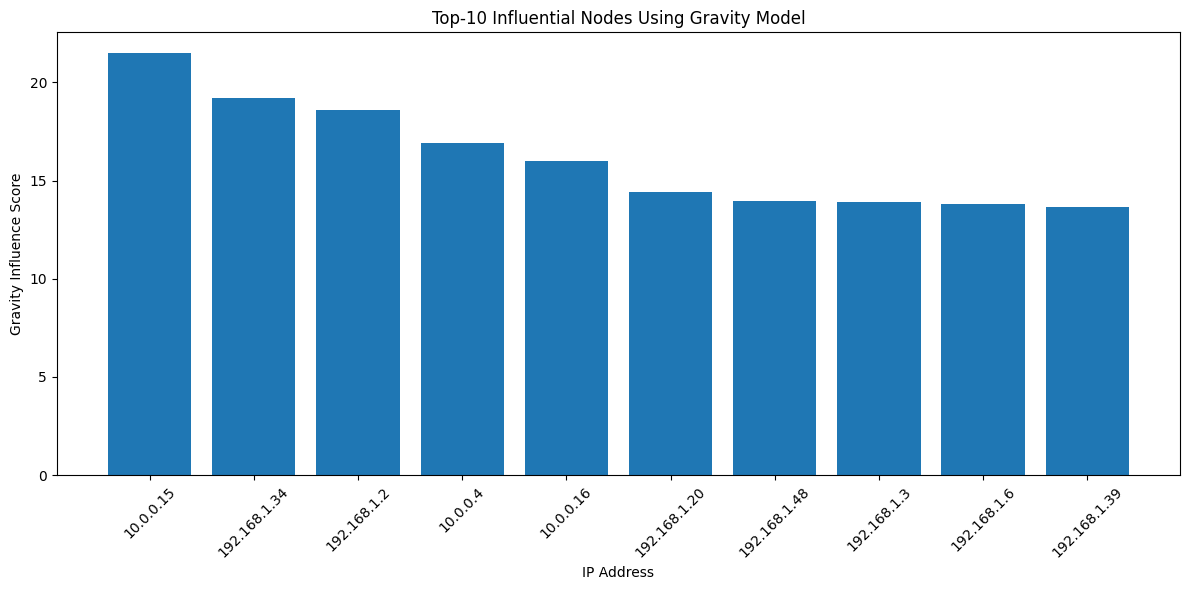

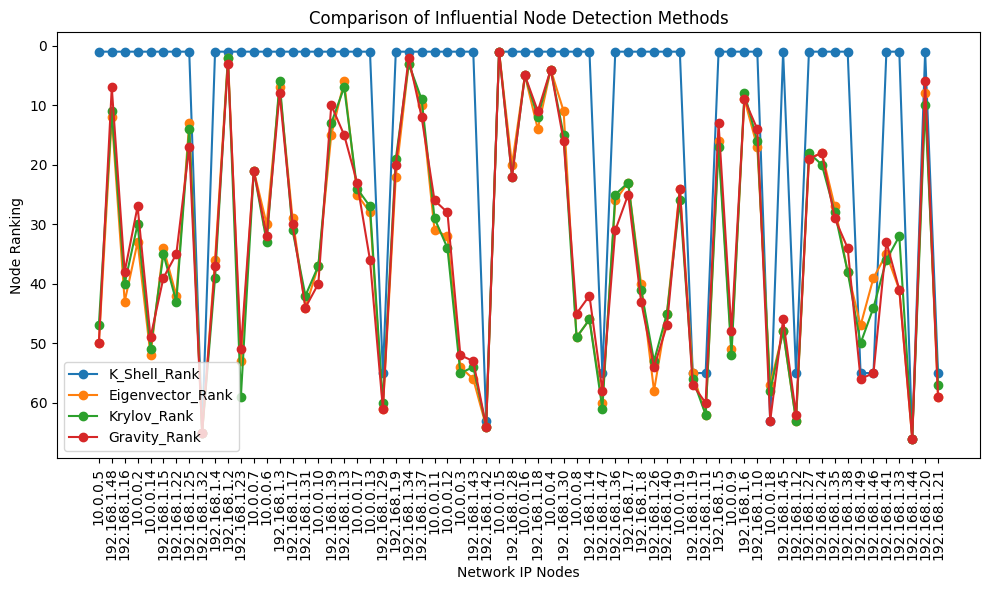

In [27]:
# ==========================================
# TOP-10 GRAVITY SCORE VISUALIZATION
# ==========================================

plt.figure(figsize=(12, 6))

plt.bar(
    gravity_top10["IP_Address"].astype(str),
    gravity_top10["Gravity_Score"]
)

plt.xlabel("IP Address")
plt.ylabel("Gravity Influence Score")

plt.title("Top-10 Influential Nodes Using Gravity Model")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


# ==========================================
# COMPARE TOP-10 RANKINGS
# ==========================================

methods = [
    "K_Shell_Rank",
    "Eigenvector_Rank",
    "Krylov_Rank",
    "Gravity_Rank"
]

plt.figure(figsize=(10, 6))

for method in methods:

    plt.plot(
        results["IP_Address"].astype(str),
        results[method],
        marker="o",
        label=method
    )

plt.xlabel("Network IP Nodes")
plt.ylabel("Node Ranking")

plt.title("Comparison of Influential Node Detection Methods")

plt.xticks(rotation=90)

plt.gca().invert_yaxis()

plt.legend()

plt.tight_layout()
plt.show()

In [28]:
ks_set = set(top10_ks["IP_Address"])
ev_set = set(top10_ev["IP_Address"])
krylov_set = set(top10_krylov["IP_Address"])
gravity_set = set(top10_gravity["IP_Address"])

overlap = pd.DataFrame({

    "Method": [
        "K-Shell",
        "Eigenvector",
        "Krylov",
        "Gravity"
    ],

    "Top10_Common_With_Gravity": [
        len(ks_set & gravity_set),
        len(ev_set & gravity_set),
        len(krylov_set & gravity_set),
        len(gravity_set)
    ]
})

display(overlap)

print("Unique nodes identified by Gravity compared with all baselines:")

unique_gravity = gravity_set - (ks_set | ev_set | krylov_set)

print(unique_gravity)

,Method,Top10_Common_With_Gravity
0,K-Shell,2
1,Eigenvector,8
2,Krylov,8
3,Gravity,10


Unique nodes identified by Gravity compared with all baselines:
{'192.168.1.39'}


In [29]:
# Improved non-trivial Krylov walk influence

A = nx.to_numpy_array(
    G,
    nodelist=nodes,
    weight="weight"
)

# Symmetric normalized adjacency matrix
degree = A.sum(axis=1)

D_inv = np.zeros_like(degree)

D_inv[degree > 0] = 1 / np.sqrt(degree[degree > 0])

A_norm = (
    D_inv[:, None] *
    A *
    D_inv[None, :]
)

# Initial vector
x = np.ones(len(nodes))

# Normalize initial vector
x = x / (np.linalg.norm(x) + 1e-12)

krylov = np.zeros(len(nodes))

# Three Krylov iterations
for k in range(1, 4):

    x = A_norm @ x

    # Normalize each iteration
    x = x / (np.linalg.norm(x) + 1e-12)

    krylov += x

# Normalize final influence
krylov = normalize(krylov)

print("Krylov influence calculated successfully")

Krylov influence calculated successfully


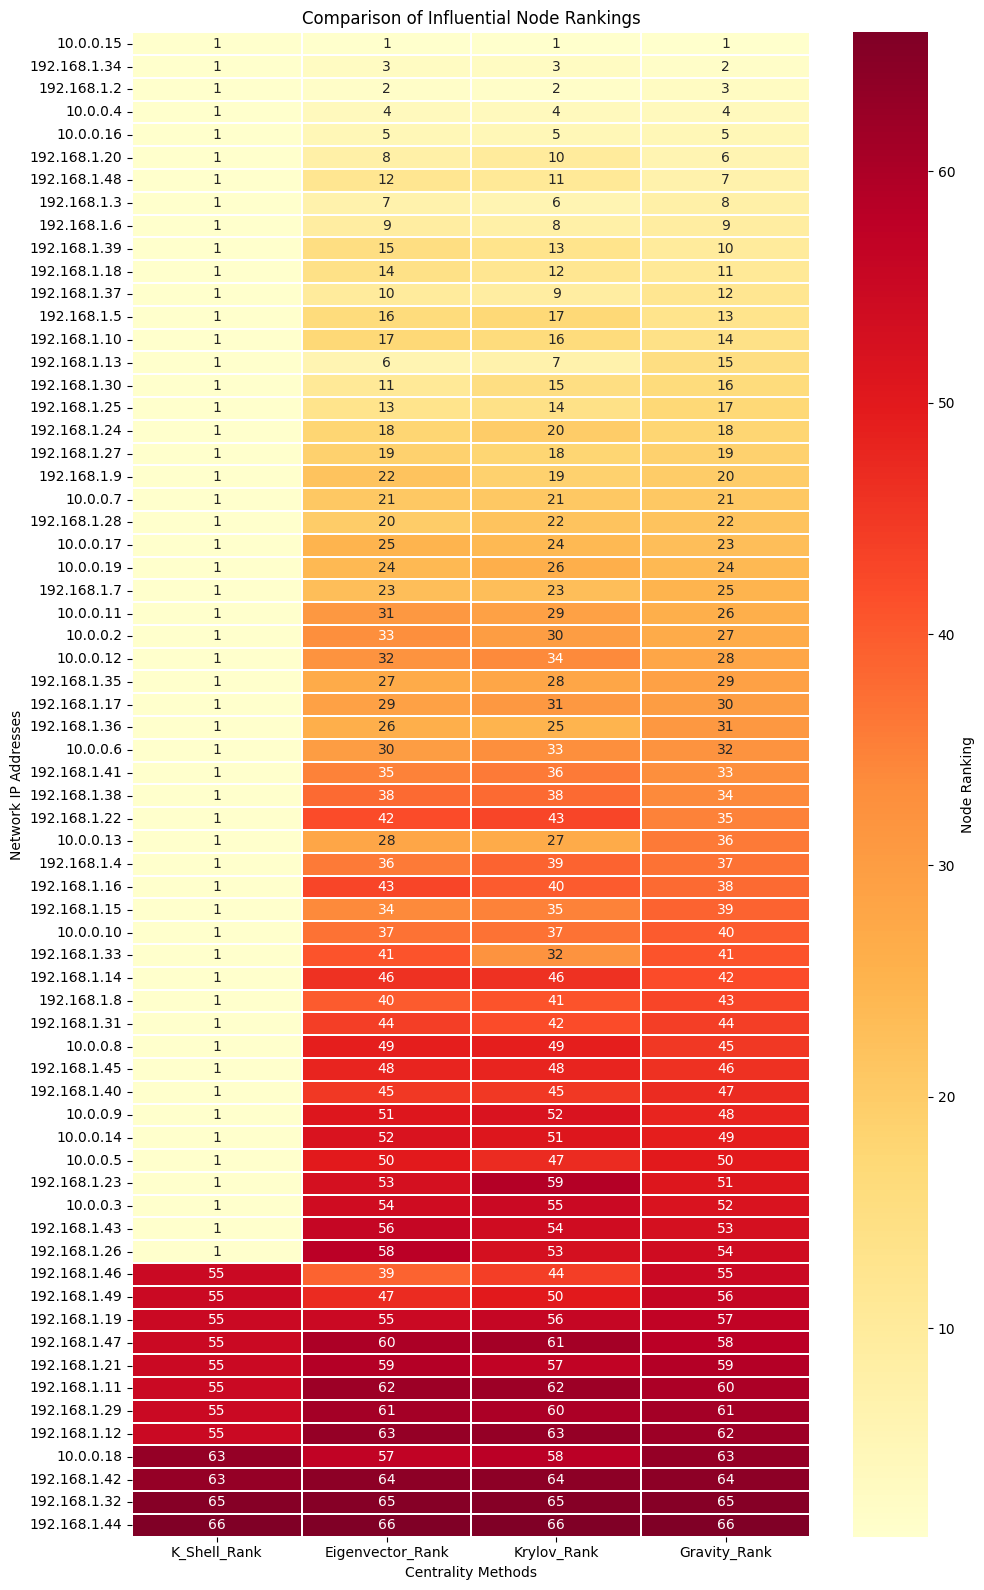

In [30]:
import seaborn as sns
import matplotlib.pyplot as plt

rank_data = results.set_index("IP_Address")[
    [
        "K_Shell_Rank",
        "Eigenvector_Rank",
        "Krylov_Rank",
        "Gravity_Rank"
    ]
]

plt.figure(figsize=(10, 16))

sns.heatmap(
    rank_data.sort_values("Gravity_Rank"),
    annot=True,
    fmt=".0f",
    cmap="YlOrRd",
    linewidths=0.3,
    cbar_kws={"label": "Node Ranking"}
)

plt.title("Comparison of Influential Node Rankings")
plt.xlabel("Centrality Methods")
plt.ylabel("Network IP Addresses")

plt.tight_layout()
plt.show()

In [31]:
results["K_Shell_Rank"] = (
    results["K_Shell"]
    .rank(ascending=False, method="average")
)

results["Eigenvector_Rank"] = (
    results["Eigenvector"]
    .rank(ascending=False, method="average")
)

results["Krylov_Rank"] = (
    results["Krylov"]
    .rank(ascending=False, method="average")
)

results["Gravity_Rank"] = (
    results["Gravity_Score"]
    .rank(ascending=False, method="average")
)

In [35]:
# Existing network
print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())

nodes = list(G.nodes())

# Sort results into exactly the same node order
results = results.set_index("IP_Address").reindex(nodes).reset_index()

# Create node features
node_features = pd.DataFrame({
    "IP_Address": nodes,

    "Degree": [G.degree(n) for n in nodes],

    "Weighted_Degree": [
        G.degree(n, weight="weight") for n in nodes
    ],

    "K_Shell": results["K_Shell"].values,

    "Eigenvector": results["Eigenvector"].values,

    "Krylov": results["Krylov"].values,

    "Clustering": [
        nx.clustering(G, n) for n in nodes
    ],

    "Betweenness": [
        nx.betweenness_centrality(G, weight=None)[n]
        for n in nodes
    ]
})

print("Node feature matrix:", node_features.shape)

display(node_features.head(10))

Nodes: 66
Edges: 446
Node feature matrix: (66, 8)


,IP_Address,Degree,Weighted_Degree,K_Shell,Eigenvector,Krylov,Clustering,Betweenness
0,10.0.0.5,12,14.0,10,0.098053,0.336435,0.212121,0.010556
1,192.168.1.48,18,19.0,10,0.145423,0.586782,0.169935,0.023239
2,192.168.1.16,14,15.0,10,0.107102,0.375025,0.197802,0.014006
3,10.0.0.2,14,15.0,10,0.114589,0.418939,0.219780,0.012107
4,10.0.0.14,12,13.0,10,0.094876,0.301854,0.121212,0.010924
5,192.168.1.15,12,15.0,10,0.113874,0.407413,0.151515,0.010789
6,192.168.1.22,13,13.0,10,0.109037,0.363563,0.205128,0.010838
7,192.168.1.25,16,19.0,10,0.145332,0.573949,0.200000,0.020770
8,192.168.1.32,7,7.0,7,0.050374,0.043859,0.190476,0.003275
9,192.168.1.4,13,15.0,10,0.111618,0.391012,0.102564,0.011673


In [36]:
import torch
print("PyTorch version:", torch.__version__)

# Install torch-geometric directly without forcing native wheel compilation
!pip install -q torch-geometric

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
import torch.nn.functional as F

from torch_geometric.data import Data
from torch_geometric.nn import GCNConv, GATConv, SAGEConv

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("All libraries imported successfully!")

PyTorch version: 2.14.1+cpu
All libraries imported successfully!


In [39]:
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GCNConv, GATConv, SAGEConv

# ==========================================
# GNN ARCHITECTURES
# ==========================================

class GCNNet(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels):
        super().__init__()
        self.conv1 = GCNConv(in_channels, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, out_channels)

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=0.2, training=self.training)
        x = self.conv2(x, edge_index)
        return x

class GATNet(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels, heads=2):
        super().__init__()
        self.conv1 = GATConv(in_channels, hidden_channels, heads=heads, concat=True)
        self.conv2 = GATConv(hidden_channels * heads, out_channels, heads=1, concat=False)

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=0.2, training=self.training)
        x = self.conv2(x, edge_index)
        return x

class SAGENet(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels):
        super().__init__()
        self.conv1 = SAGEConv(in_channels, hidden_channels)
        self.conv2 = SAGEConv(hidden_channels, out_channels)

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=0.2, training=self.training)
        x = self.conv2(x, edge_index)
        return x

print("GCN, GAT, and GraphSAGE model architectures defined successfully!")

GCN, GAT, and GraphSAGE model architectures defined successfully!


In [40]:
# ==========================================
# STEP 1: PREPARE NODE FEATURES & LABELS
# ==========================================
import torch
import numpy as np
import pandas as pd
import networkx as nx
from sklearn.preprocessing import StandardScaler
from torch_geometric.data import Data

# Ensure RANDOM_STATE is defined
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

# We will use our extracted node features:
feature_cols_gnn = ['Degree', 'Weighted_Degree', 'K_Shell', 'Eigenvector', 'Krylov', 'Clustering', 'Betweenness']
x_raw = node_features[feature_cols_gnn].values

# Standardize node features
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x_raw)
x_tensor = torch.tensor(x_scaled, dtype=torch.float)

# Labels: Create synthetic pseudo-ground truth labels based on gravity score thresholds
# Class 1: High-influence nodes (Gravity Score > median), Class 0: Low-influence nodes
gravity_threshold = results["Gravity_Score"].median()
y_raw = (results["Gravity_Score"].values > gravity_threshold).astype(int)
y_tensor = torch.tensor(y_raw, dtype=torch.long)

# ==========================================
# STEP 2: CONVERT NETWORKX EDGES TO PYG COO
# ==========================================

# Map IP node names to integer indices
node_to_idx = {node: idx for idx, node in enumerate(nodes)}

edge_index_list = []
for u, v in G.edges():
    u_idx, v_idx = node_to_idx[u], node_to_idx[v]
    # Undirected graph requires both directions
    edge_index_list.append([u_idx, v_idx])
    edge_index_list.append([v_idx, u_idx])

edge_index_tensor = torch.tensor(edge_index_list, dtype=torch.long).t().contiguous()

# ==========================================
# STEP 3: CREATE SEMI-SUPERVISED MASKS
# ==========================================

num_nodes = len(nodes)
indices = np.random.permutation(num_nodes)

# 60/20/20 node split
train_split = int(0.6 * num_nodes)
val_split = int(0.8 * num_nodes)

train_mask = np.zeros(num_nodes, dtype=bool)
val_mask = np.zeros(num_nodes, dtype=bool)
test_mask = np.zeros(num_nodes, dtype=bool)

train_mask[indices[:train_split]] = True
val_mask[indices[train_split:val_split]] = True
test_mask[indices[val_split:]] = True

train_mask_tensor = torch.tensor(train_mask, dtype=torch.bool)
val_mask_tensor = torch.tensor(val_mask, dtype=torch.bool)
test_mask_tensor = torch.tensor(test_mask, dtype=torch.bool)

# Build PyG Data object
data = Data(
    x=x_tensor,
    edge_index=edge_index_tensor,
    y=y_tensor,
    train_mask=train_mask_tensor,
    val_mask=val_mask_tensor,
    test_mask=test_mask_tensor
)

print("=== PyTorch Geometric Data Struct ===")
print(data)
print("Number of training nodes:", data.train_mask.sum().item())
print("Number of validation nodes:", data.val_mask.sum().item())
print("Number of test nodes:", data.test_mask.sum().item())

=== PyTorch Geometric Data Struct ===
Data(x=[66, 7], edge_index=[2, 892], y=[66], train_mask=[66], val_mask=[66], test_mask=[66])
Number of training nodes: 39
Number of validation nodes: 13
Number of test nodes: 14


In [41]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def train_model(model, data, epochs=200, lr=0.01, weight_decay=5e-4):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    criterion = nn.CrossEntropyLoss()

    best_val_f1 = 0.0
    best_test_metrics = {}

    for epoch in range(1, epochs + 1):
        model.train()
        optimizer.zero_grad()
        out = model(data.x, data.edge_index)
        loss = criterion(out[data.train_mask], data.y[data.train_mask])
        loss.backward()
        optimizer.step()

        # Evaluate
        model.eval()
        with torch.no_grad():
            logits = model(data.x, data.edge_index)
            preds = logits.argmax(dim=-1).cpu().numpy()
            targets = data.y.cpu().numpy()

            # Metrics
            val_acc = accuracy_score(targets[data.val_mask], preds[data.val_mask])
            val_f1 = f1_score(targets[data.val_mask], preds[data.val_mask], average='binary', zero_division=0)

            test_acc = accuracy_score(targets[data.test_mask], preds[data.test_mask])
            test_prec = precision_score(targets[data.test_mask], preds[data.test_mask], average='binary', zero_division=0)
            test_rec = recall_score(targets[data.test_mask], preds[data.test_mask], average='binary', zero_division=0)
            test_f1 = f1_score(targets[data.test_mask], preds[data.test_mask], average='binary', zero_division=0)

            if val_f1 > best_val_f1:
                best_val_f1 = val_f1
                best_test_metrics = {
                    "accuracy": test_acc,
                    "precision": test_prec,
                    "recall": test_rec,
                    "f1": test_f1
                }

    return best_test_metrics

# Initialize models
in_feats = data.num_features
hid_feats = 16
out_classes = 2

gcn_model = GCNNet(in_feats, hid_feats, out_classes)
gat_model = GATNet(in_feats, hid_feats, out_classes)
sage_model = SAGENet(in_feats, hid_feats, out_classes)

# Train and evaluate
gcn_results = train_model(gcn_model, data)
gat_results = train_model(gat_model, data)
sage_results = train_model(sage_model, data)

# Compare GNN Performance
performance_df = pd.DataFrame({
    "GCN": gcn_results,
    "GAT": gat_results,
    "GraphSAGE": sage_results
}).T

print("=== GNN MODEL COMPARISON BENCHMARK ===")
display(performance_df)

=== GNN MODEL COMPARISON BENCHMARK ===


,accuracy,precision,recall,f1
GCN,0.500000,0.625000,0.555556,0.588235
GAT,0.500000,0.666667,0.444444,0.533333
GraphSAGE,0.928571,1.000000,0.888889,0.941176


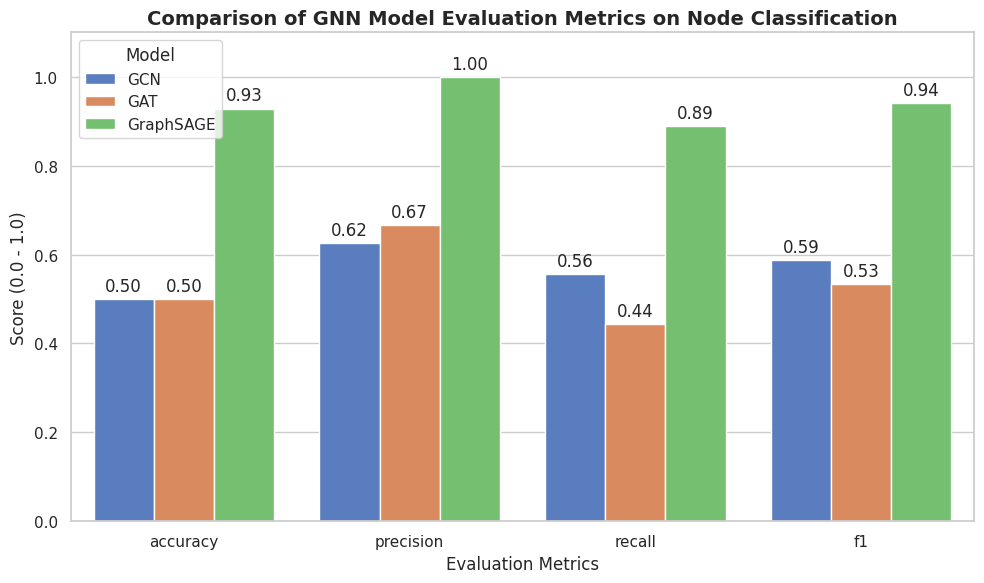

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare data for plotting
plot_df = performance_df.reset_index().rename(columns={'index': 'Model'})
plot_df_melted = plot_df.melt(id_vars='Model', var_name='Metric', value_name='Score')

plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Create a bar plot grouping metrics by GNN architecture
ax = sns.barplot(
    data=plot_df_melted,
    x='Metric',
    y='Score',
    hue='Model',
    palette='muted'
)

plt.title('Comparison of GNN Model Evaluation Metrics on Node Classification', fontsize=14, fontweight='bold')
plt.xlabel('Evaluation Metrics', fontsize=12)
plt.ylabel('Score (0.0 - 1.0)', fontsize=12)
plt.ylim(0.0, 1.1)

# Annotate the actual score values on top of the bars
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3)

plt.tight_layout()
plt.show()

In [42]:
# ==========================================
# MODEL 1: GCN
# ==========================================

class GCN(torch.nn.Module):

    def __init__(self, input_dim, hidden_dim, num_classes):

        super().__init__()

        self.conv1 = GCNConv(input_dim, hidden_dim)
        self.conv2 = GCNConv(hidden_dim, hidden_dim)

        self.fc = torch.nn.Linear(
            hidden_dim, num_classes
        )

    def forward(self, x, edge_index):

        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=0.3, training=self.training)

        x = self.conv2(x, edge_index)
        x = F.relu(x)

        return self.fc(x)


# ==========================================
# MODEL 2: GAT
# ==========================================

class GAT(torch.nn.Module):

    def __init__(self, input_dim, hidden_dim, num_classes):

        super().__init__()

        self.conv1 = GATConv(
            input_dim,
            hidden_dim,
            heads=4,
            dropout=0.3
        )

        self.conv2 = GATConv(
            hidden_dim * 4,
            hidden_dim,
            heads=1,
            concat=False,
            dropout=0.3
        )

        self.fc = torch.nn.Linear(
            hidden_dim, num_classes
        )

    def forward(self, x, edge_index):

        x = self.conv1(x, edge_index)
        x = F.elu(x)
        x = F.dropout(x, p=0.3, training=self.training)

        x = self.conv2(x, edge_index)
        x = F.elu(x)

        return self.fc(x)


# ==========================================
# MODEL 3: GRAPHSAGE
# ==========================================

class GraphSAGE(torch.nn.Module):

    def __init__(self, input_dim, hidden_dim, num_classes):

        super().__init__()

        self.conv1 = SAGEConv(input_dim, hidden_dim)
        self.conv2 = SAGEConv(hidden_dim, hidden_dim)

        self.fc = torch.nn.Linear(
            hidden_dim, num_classes
        )

    def forward(self, x, edge_index):

        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=0.3, training=self.training)

        x = self.conv2(x, edge_index)
        x = F.relu(x)

        return self.fc(x)


print("GCN, GAT and GraphSAGE architectures created!")

GCN, GAT and GraphSAGE architectures created!


In [46]:
# ==========================================
# TRAINING FUNCTION
# ==========================================
import torch
import torch.nn.functional as F
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def train_model(model, model_name, epochs=200):
    model = model.to(device)
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.005,
        weight_decay=0.001
    )

    # Handle class imbalance using training labels
    train_labels = data.y[data.train_mask]
    counts = torch.bincount(
        train_labels,
        minlength=2
    ).float()

    class_weights = (
        counts.sum() / (2 * counts.clamp(min=1))
    )

    criterion = torch.nn.CrossEntropyLoss(
        weight=class_weights.to(device)
    )

    best_val_loss = float("inf")
    best_state = None

    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        output = model(data.x.to(device), data.edge_index.to(device))
        loss = criterion(
            output[data.train_mask],
            data.y[data.train_mask].to(device)
        )
        loss.backward()
        optimizer.step()

        # Validation
        model.eval()
        with torch.no_grad():
            output = model(data.x.to(device), data.edge_index.to(device))
            val_loss = criterion(
                output[data.val_mask],
                data.y[data.val_mask].to(device)
            ).item()

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

        if (epoch + 1) % 25 == 0:
            print(
                f"{model_name} | Epoch {epoch+1} | "
                f"Train Loss: {loss.item():.4f} | "
                f"Validation Loss: {val_loss:.4f}"
            )

    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        logits = model(data.x.to(device), data.edge_index.to(device))
        probabilities = F.softmax(logits, dim=1)
        predictions = logits.argmax(dim=1)

    y_true = data.y[data.test_mask].cpu().numpy()
    y_pred = predictions[data.test_mask].cpu().numpy()

    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "F1_Score": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        )
    }

    return model, metrics, predictions.cpu(), probabilities.cpu()

# Initialize models
num_classes = 2
models = {
    "GCN": GCN(data.num_features, 32, num_classes),
    "GAT": GAT(data.num_features, 32, num_classes),
    "GraphSAGE": GraphSAGE(data.num_features, 32, num_classes)
}

trained_models = {}
all_metrics = {}
all_predictions = {}
all_probabilities = {}

for name, model in models.items():
    print("\nTraining", name)
    trained, metrics, predictions, probabilities = train_model(
        model, name
    )
    trained_models[name] = trained
    all_metrics[name] = metrics
    all_predictions[name] = predictions
    all_probabilities[name] = probabilities

print("\nAll GNN models trained!")


Training GCN
GCN | Epoch 25 | Train Loss: 0.4959 | Validation Loss: 0.5394
GCN | Epoch 50 | Train Loss: 0.4057 | Validation Loss: 0.4819
GCN | Epoch 75 | Train Loss: 0.3681 | Validation Loss: 0.4642
GCN | Epoch 100 | Train Loss: 0.3215 | Validation Loss: 0.4540
GCN | Epoch 125 | Train Loss: 0.2670 | Validation Loss: 0.4903
GCN | Epoch 150 | Train Loss: 0.1991 | Validation Loss: 0.5613
GCN | Epoch 175 | Train Loss: 0.1822 | Validation Loss: 0.6232
GCN | Epoch 200 | Train Loss: 0.2599 | Validation Loss: 0.6799

Training GAT
GAT | Epoch 25 | Train Loss: 0.5289 | Validation Loss: 0.5569
GAT | Epoch 50 | Train Loss: 0.4391 | Validation Loss: 0.5350
GAT | Epoch 75 | Train Loss: 0.4197 | Validation Loss: 0.4267
GAT | Epoch 100 | Train Loss: 0.3277 | Validation Loss: 0.3764
GAT | Epoch 125 | Train Loss: 0.5076 | Validation Loss: 0.4245
GAT | Epoch 150 | Train Loss: 0.3323 | Validation Loss: 0.5962
GAT | Epoch 175 | Train Loss: 0.4180 | Validation Loss: 0.5228
GAT | Epoch 200 | Train Loss: 0.2

In [47]:
# ==========================================
# PERFORMANCE COMPARISON
# ==========================================

performance = pd.DataFrame(
    list(all_metrics.values())
)

print("GNN MODEL PERFORMANCE")
display(performance.round(4))

performance.to_csv(
    "GNN_Performance_Comparison.csv",
    index=False
)

GNN MODEL PERFORMANCE


,Model,Accuracy,Precision,Recall,F1_Score
0,GCN,0.7143,0.7778,0.7778,0.7143
1,GAT,0.8571,0.8571,0.8889,0.8542
2,GraphSAGE,0.9286,0.9167,0.9444,0.9251


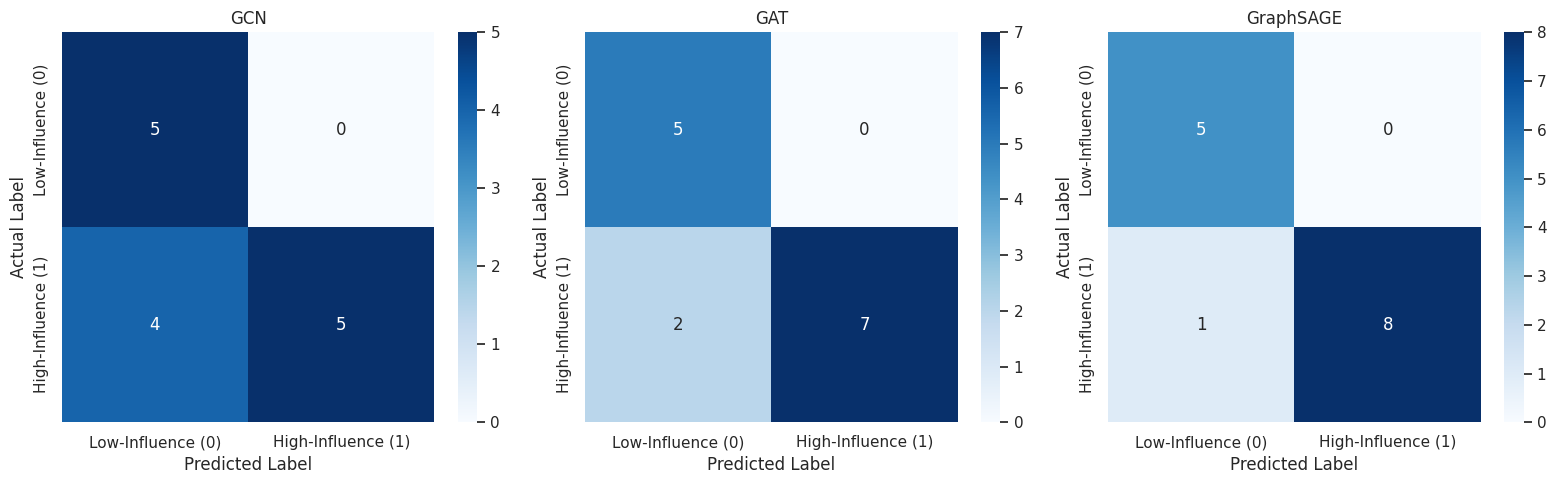

In [49]:
# ==========================================
# CONFUSION MATRICES
# ==========================================

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Map integer labels directly
class_names = ['Low-Influence (0)', 'High-Influence (1)']

for ax, name in zip(axes, models.keys()):

    y_true = data.y[data.test_mask].cpu().numpy()

    y_pred = all_predictions[name][
        data.test_mask.cpu()
    ].numpy()

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=np.arange(num_classes)
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax,
        xticklabels=class_names,
        yticklabels=class_names
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

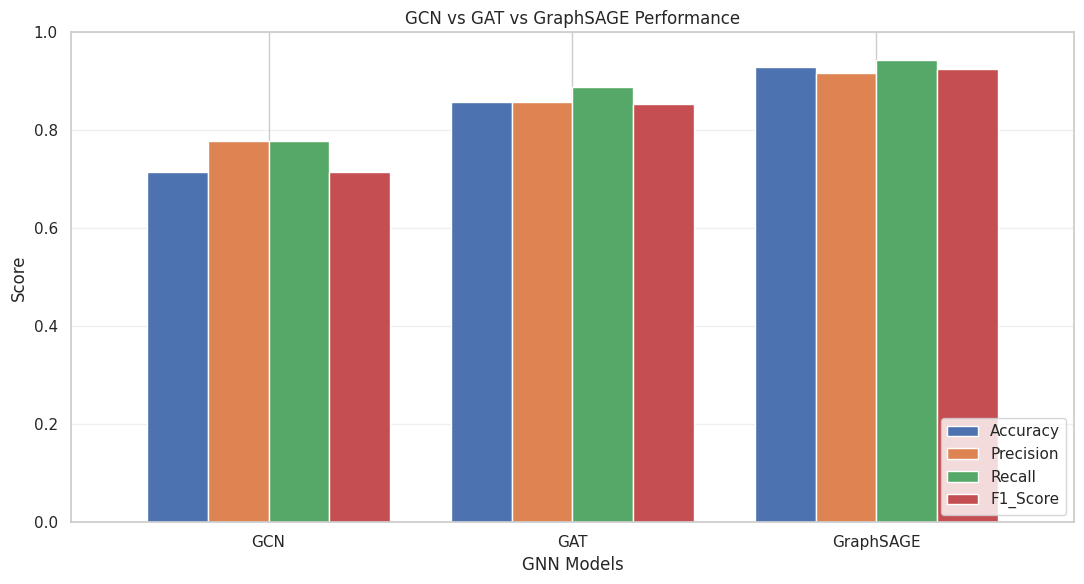

In [50]:
# ==========================================
# PERFORMANCE BAR CHART
# ==========================================

metrics_to_plot = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1_Score"
]

performance_plot = performance.set_index("Model")[
    metrics_to_plot
]

performance_plot.plot(
    kind="bar",
    figsize=(11, 6),
    ylim=(0, 1),
    width=0.8
)

plt.title("GCN vs GAT vs GraphSAGE Performance")
plt.ylabel("Score")
plt.xlabel("GNN Models")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()